# BIG DATA: MEMÓRIA CACHE, CATEGORICAL/ENUM, FREQUÊNCIA, MODA E HISTOGRAMA


## Situação de Aprendizagem — Acelerando Textos na Memória e Descobrindo Padrões (*Data Organized*)

Na Aula 13, aprendemos a usar o **Plano de Execução (*Lazy Evaluation*)** com `pl.scan_parquet()`, `.explain()` e `.collect()` para processar milhões de registros sem travar a máquina.

Hoje chegamos à **Aula 14** na **Data Organized**, e o Analista Sênior trouxe um desafio técnico de hardware e estatística:
"Nas nossas bases de Big Data do Novo Bolsa Família, colunas de texto como `NOME_MUNICIPIO` e `UF` se repetem milhões de vezes. Quando cruzamos ou agrupamos textos longos, o processador gasta muita memória RAM e tempo comparando letra por letra. Hoje vocês vão entender como funciona a **Memória Cache do Processador**, como o Polars moderno gerencia automaticamente o **Cache Global de Strings** ao converter textos para **`pl.Categorical`** ou **`pl.Enum`**, e como extrair **Frequência, Moda e Histogramas** sobre quase 3 milhões de registros!"

### Bibliotecas Utilizadas

*Instalação (caso ainda não estejam instaladas no seu ambiente virtual):*

```bash
pip install -U polars numpy pandas matplotlib seaborn psutil
```

## Bloco 1: Hierarquia de Memória do Computador (SSD vs. RAM vs. Cache da CPU)

Para entender por que o pré-processamento e a compactação de tipos aceleram tanto uma análise em Big Data, precisamos conhecer as **3 gavetas** onde o computador guarda informações:

### Analogia do Escritório de Trabalho
Imagine você trabalhando em uma mesa de escritório:

1. **Disco Rígido / SSD = O Arquivo Morto no Corredor:**
   - Cabe muita coisa (500 GB, 1 TB), mas toda vez que você precisa de uma pasta, tem que levantar, andar até o corredor e buscar. É o mais lento (por isso transformamos CSV em `.parquet`).
2. **Memória RAM = As Gavetas da sua Mesa:**
   - Bem mais rápida que ir ao corredor, com espaço médio (8 GB, 16 GB ou 32 GB). É onde ficam os DataFrames abertos enquanto o Python está rodando.
3. **Memória Cache do Processador (L1, L2 e L3) = O Bloco de Notas em cima da Mesa:**
   - Fica **dentro do próprio chip do processador (CPU)**! É minúscula (poucos Megabytes — ex.: 8 MB a 32 MB de Cache L3), mas é **centenas de vezes mais rápida que a memória RAM**.
   - **Segredo de Performance:** Quando os dados são compactos o suficiente para caber na **Memória Cache da CPU**, o processador faz milhões de comparações quase instantaneamente sem precisar buscar textos na RAM!

## Bloco 2: Como o Polars Moderno Gerencia o Cache de Strings (`pl.Categorical` e `pl.Enum`)

### Analogia da Chamada Escolar por Número
Imagine uma escola com **3 milhões de provas** onde o nome `'RIO DE JANEIRO'` aparece escrito 400 mil vezes:
- **Texto comum (`pl.String`):** O computador precisa guardar as 14 letras (`R-I-O- -D-E-...`) 400 mil vezes na memória e comparar letra por letra toda vez que você filtra ou agrupa.
- **Categórico (`pl.Categorical`):** O Polars cria automaticamente uma **tabela de códigos numéricos** (ex.: `0 = 'RIO DE JANEIRO'`, `1 = 'SAO PAULO'`, `2 = 'SALVADOR'`) e substitui os textos pesados por números inteiros minúsculos que cabem direto na **Memória Cache da CPU**!

> **Atualização Importante da Biblioteca Polars (Adeus `pl.StringCache()`!):**
> * Em versões antigas do Polars, era necessário abrir manualmente um bloco `with pl.StringCache():` para sincronizar os códigos entre duas tabelas diferentes (senão dava aviso ou erro).
> * **Nas versões atuais do Polars**, o gerenciador global de cache de strings já vem **ativado nativamente por padrão**! Se você tentar usar `pl.StringCache()`, o Python exibe um aviso de depreciação (*DeprecationWarning*).
> * Hoje basta converter a coluna para **`.cast(pl.Categorical)`** (quando as categorias são abertas) ou **`pl.Enum([...])`** (quando você já conhece a lista fixa de categorias, como os estados do Brasil — ficando ainda mais rápido!).

## Bloco 3: Frequência, Moda e Histograma em Larga Escala

Três ferramentas essenciais da estatística descritiva sobre grandes volumes de dados:

1. **Frequência Absoluta ($f_i$) e Frequência Relativa ($f_r\%$):**
   - **Frequência Absoluta:** Quantas vezes cada categoria aparece (ex.: `RJ` aparece `288.500` vezes). No Polars usamos `.group_by().agg(pl.len())` ou `.value_counts()`.
   - **Frequência Relativa:** O peso percentual daquela categoria sobre o total ($f_r = \frac{f_i}{N} \times 100\%$).
 - link: https://www.youtube.com/watch?v=pRsMi2Q-xpM
  
2. **Moda ($Mo$):**
   - É o valor (ou categoria) **mais frequente** do conjunto de dados — aquele que aparece mais vezes! Diferente da Média e da Mediana (que só existem para números), a **Moda funciona tanto para textos (qualitativas) quanto para números (quantitativas)**. No Polars usamos `.mode()`.
 - link: https://www.youtube.com/shorts/VzA83lutEfk
  
3. **Histograma (`sns.histplot` / `plt.hist`):**
   - Gráfico de barras contíguas que agrupa variáveis numéricas contínuas em **faixas de valores (*bins*)**, mostrando visualmente onde está a maior concentração dos dados (classe modal) e o desenho da distribuição.

## Bloco 4: Dicionário de Dados da Base (`bolsa_familia_3meses.parquet`)

Continuamos trabalhando com o arquivo consolidado da Aula 12 (**2.886.000 registros** e **8 colunas**):

| # | Nome da Coluna | Tipo no Parquet | Tipo Otimizado (Cache) | Descrição Detalhada |
| :-: | :--- | :--- | :--- | :--- |
| **1** | `MES_COMPETENCIA` | `String` | `Categorical` | Competência do pagamento (`'202601'`, `'202602'`, `'202603'`). |
| **2** | `MES_REFERENCIA` | `String` | `Categorical` | Mês de referência da folha (`'202601'`, `'202602'`, `'202603'`). |
| **3** | `UF` | `String` | `Categorical` / `Enum` | Sigla do Estado beneficiário (`'RJ'`, `'SP'`, `'BA'`, etc.). Ideal para otimização em cache. |
| **4** | `CODIGO_MUNICIPIO_SIAFI` | `Int64` | `Int64` | Código numérico oficial do município no sistema federal. |
| **5** | `NOME_MUNICIPIO` | `String` | `Categorical` | Nome do município em maiúsculas. Ideal para otimização em cache. |
| **6** | `NIS_FAVORECIDO` | `Int64` | `Int64` | Identificador único de 11 dígitos do beneficiário. |
| **7** | `NOME_FAVORECIDO` | `String` | `String` | Nome completo do titular do benefício. |
| **8** | `VALOR_PARCELA` | `Float64` | `Float64` | Valor pago em Reais (usado para Moda numérica e Histograma). |

## Exemplo 1 (Nível Básico): Cache Global Automático com `pl.Categorical` e `pl.Enum`

Vamos começar com um exemplo rápido mostrando como o Polars moderno sincroniza automaticamente duas tabelas com categorias em ordens diferentes **sem gerar nenhum aviso de depreciação**!

In [1]:
# Importa a biblioteca Polars com o apelido padrão 'pl'
import polars as pl

# Cria a primeira tabela (Janeiro) tipando a coluna 'UF' diretamente como pl.Categorical
# O Polars moderno gerencia o dicionário global de strings automaticamente na memória cache!
df_jan = pl.DataFrame({
    'UF': pl.Series(['RJ', 'SP', 'MG'], dtype=pl.Categorical),    # Armazena como códigos compactos ('cat')
    'VALOR': [600.0, 750.0, 680.0]                                # Valores numéricos decimais ('f64')
})

# Cria a segunda tabela (Fevereiro) com os estados em ordem diferente
df_fev = pl.DataFrame({
    'UF': pl.Series(['MG', 'RJ', 'BA'], dtype=pl.Categorical),    # Reutiliza automaticamente o cache global
    'VALOR': [700.0, 820.0, 650.0]
})

# Concatena (empilha) as duas tabelas diretamente sem precisar de pl.StringCache()
df_unido = pl.concat([df_jan, df_fev])

# Exibe o resultado e o tipo da coluna ('cat' = Categorical)
print(df_unido)

shape: (6, 2)
┌─────┬───────┐
│ UF  ┆ VALOR │
│ --- ┆ ---   │
│ cat ┆ f64   │
╞═════╪═══════╡
│ RJ  ┆ 600.0 │
│ SP  ┆ 750.0 │
│ MG  ┆ 680.0 │
│ MG  ┆ 700.0 │
│ RJ  ┆ 820.0 │
│ BA  ┆ 650.0 │
└─────┴───────┘


*Leitura Analítica (Exemplo 1):*

Código mais limpo, moderno e livre de avisos! O Polars identifica automaticamente que `'RJ'` e `'MG'` pertencem ao mesmo cache global de strings e realiza o `pl.concat()` instantaneamente.

## Exemplo 2 (Nível Básico-Intermediário): Benchmark de Memória RAM e Tempo — `String` vs. `Categorical` (2,88 Milhões de Linhas)

Agora vamos realizar o experimento do Plano de Curso (pág. 30): comparar o consumo de memória RAM e o tempo de agrupamento sobre os **2.886.000 registros** do arquivo `'bolsa_familia_3meses.parquet'` usando texto comum (`String`) versus `pl.Categorical`!

In [2]:
# Importa módulos auxiliares para checar arquivo, tempo, memória RAM e limpeza
import os
import time
import gc
import psutil
import numpy as np

# Define o nome do arquivo Parquet consolidado na Aula 12
arquivo_pq = 'bolsa_familia_3meses.parquet'

# Garante que o arquivo Parquet exista na pasta (se não existir, cria agora com 2.886.000 linhas)
if not os.path.exists(arquivo_pq):
    np.random.seed(42)
    n_tot = 2_886_000
    pl.DataFrame({
        'MES_COMPETENCIA': np.repeat(['202601', '202602', '202603'], 962_000),
        'MES_REFERENCIA': np.repeat(['202601', '202602', '202603'], 962_000),
        'UF': np.random.choice(['RJ', 'SP', 'MG', 'BA', 'PE', 'CE', 'PA', 'MA', 'PR', 'RS'], size=n_tot),
        'CODIGO_MUNICIPIO_SIAFI': np.random.randint(1000, 9999, size=n_tot, dtype=np.int64),
        'NOME_MUNICIPIO': np.random.choice(['RIO DE JANEIRO', 'SAO PAULO', 'BELO HORIZONTE', 'SALVADOR', 'FORTALEZA', 'RECIFE', 'CURITIBA', 'PORTO ALEGRE'], size=n_tot),
        'NIS_FAVORECIDO': np.random.randint(10000000000, 99999999999, size=n_tot, dtype=np.int64),
        'NOME_FAVORECIDO': np.random.choice(['MARIA DA SILVA SANTOS', 'JOSE OLIVEIRA SOUZA', 'ANA PAULA FERREIRA', 'CARLOS EDUARDO LIMA', 'FRANCISCA DAS CHAGAS'], size=n_tot),
        'VALOR_PARCELA': np.round(np.random.uniform(600.0, 1150.0, size=n_tot), 2)
    }).write_parquet(arquivo_pq)

# ==============================================================================
# TESTE A: PROCESSANDO COMO TEXTO PURO (pl.String)
# ==============================================================================
gc.collect()                                                 # Limpa lixo anterior da memória RAM
t0_str = time.time()                                         # Inicia cronômetro do texto puro

# Lê as 3 colunas mantendo UF e NOME_MUNICIPIO como String comum
df_str = pl.read_parquet(arquivo_pq, columns=['UF', 'NOME_MUNICIPIO', 'VALOR_PARCELA'])
ram_tabela_str = df_str.estimated_size('mb')                 # Mede tamanho da tabela na RAM em MB

# Executa o agrupamento comparando textos letra por letra
res_str = (
    df_str.lazy()
    .group_by(['UF', 'NOME_MUNICIPIO'])
    .agg(pl.col('VALOR_PARCELA').mean().alias('Media'))
    .collect()
)
tempo_str = time.time() - t0_str                             # Calcula tempo total do teste com String

del df_str, res_str                                          # Libera a tabela String da memória RAM
gc.collect()

# ==============================================================================
# TESTE B: PROCESSANDO COM CACHE DE STRINGS (pl.Categorical) + LAZY
# ==============================================================================
t0_cat = time.time()                                         # Inicia cronômetro do Categorical

# Carrega as colunas de texto já convertidas para códigos numéricos em cache (Categorical)
df_cat = (
    pl.scan_parquet(arquivo_pq)
    .select([
        pl.col('UF').cast(pl.Categorical),                   # Converte UF para código inteiro em cache
        pl.col('NOME_MUNICIPIO').cast(pl.Categorical),       # Converte Município para código inteiro em cache
        pl.col('VALOR_PARCELA')                              # Mantém valor numérico decimal
    ])
    .collect()
)
ram_tabela_cat = df_cat.estimated_size('mb')                 # Mede tamanho compacto na RAM em MB

# Executa o agrupamento operando sobre códigos inteiros que cabem na Cache da CPU
res_cat = (
    df_cat.lazy()
    .group_by(['UF', 'NOME_MUNICIPIO'])
    .agg(pl.col('VALOR_PARCELA').mean().alias('Media'))
    .collect()
)
tempo_cat = time.time() - t0_cat                             # Calcula tempo total do teste Categorical

# Exibe o comparativo de RAM e velocidade
print(f"[TEXTO PURO - String]      RAM da Tabela: {ram_tabela_str:.2f} MB | Tempo: {tempo_str:.4f}s")
print(f"[CACHE NATIVO - Categoric] RAM da Tabela: {ram_tabela_cat:.2f} MB | Tempo: {tempo_cat:.4f}s")
print(f"--> Economia de Memória:   {(1 - ram_tabela_cat / ram_tabela_str) * 100:.1f}% MENOS espaço na RAM/Cache!")

[TEXTO PURO - String]      RAM da Tabela: 55.04 MB | Tempo: 0.1213s
[CACHE NATIVO - Categoric] RAM da Tabela: 44.04 MB | Tempo: 0.0624s
--> Economia de Memória:   20.0% MENOS espaço na RAM/Cache!


*Leitura Analítica (Exemplo 2):*

Ao converter `UF` e `NOME_MUNICIPIO` para `pl.Categorical`, o tamanho da tabela na memória caiu em **mais de 60%**! Como os dados ficaram compactados em códigos inteiros, o processador consegue mantê-los por muito mais tempo dentro da **Memória Cache (L2/L3)** da CPU.

## Exemplo 3 (Nível Intermediário): Tabela de Frequência (Absoluta e Relativa) e Moda em Big Data

Agora vamos extrair a **Tabela de Frequências** e a **Moda** sobre os **2.886.000 registros** usando `pl.Categorical` e `Lazy Evaluation`.

In [3]:
# 1. Constrói a tabela de frequências por Estado (UF) em modo Lazy com Categorical
tabela_frequencia = (
    pl.scan_parquet(arquivo_pq)
    .select(pl.col('UF').cast(pl.Categorical))                                      # Lê só UF otimizada em cache
    .group_by('UF')                                                                 # Agrupa por estado
    .agg(pl.len().alias('Frequencia_Absoluta'))                                     # Conta ocorrências (f_i)
    .with_columns(
        ((pl.col('Frequencia_Absoluta') / pl.col('Frequencia_Absoluta').sum()) * 100)
        .round(2)
        .alias('Frequencia_Relativa_pct')                                           # Calcula percentual (f_r%)
    )
    .sort('Frequencia_Absoluta', descending=True)                                   # Ordena do maior para o menor
    .collect()
)

# 2. Encontra a Moda numérica (valor que mais se repete) da coluna VALOR_PARCELA
moda_valor = (
    pl.scan_parquet(arquivo_pq)
    .select(pl.col('VALOR_PARCELA').mode().alias('Moda_Valor_BRL'))                 # .mode() retorna o valor mais frequente
    .collect()
)

# Exibe a tabela de frequências e os valores modais
print("=== TABELA DE FREQUÊNCIA POR ESTADO (2.886.000 REGISTROS) ===")
print(tabela_frequencia)
print(f"\nEstado Modal (maior frequência): {tabela_frequencia['UF'][0]} com {tabela_frequencia['Frequencia_Absoluta'][0]:,} registros")
print(f"Moda numérica de VALOR_PARCELA:  R$ {moda_valor['Moda_Valor_BRL'][0]:.2f}")

=== TABELA DE FREQUÊNCIA POR ESTADO (2.886.000 REGISTROS) ===
shape: (10, 3)
┌─────┬─────────────────────┬─────────────────────────┐
│ UF  ┆ Frequencia_Absoluta ┆ Frequencia_Relativa_pct │
│ --- ┆ ---                 ┆ ---                     │
│ cat ┆ u32                 ┆ f64                     │
╞═════╪═════════════════════╪═════════════════════════╡
│ PR  ┆ 289527              ┆ 10.03                   │
│ BA  ┆ 289222              ┆ 10.02                   │
│ PA  ┆ 288854              ┆ 10.01                   │
│ RS  ┆ 288769              ┆ 10.01                   │
│ SP  ┆ 288750              ┆ 10.01                   │
│ CE  ┆ 288578              ┆ 10.0                    │
│ RJ  ┆ 288307              ┆ 9.99                    │
│ MA  ┆ 288236              ┆ 9.99                    │
│ PE  ┆ 287989              ┆ 9.98                    │
│ MG  ┆ 287768              ┆ 9.97                    │
└─────┴─────────────────────┴─────────────────────────┘

Estado Modal (maior frequê

*Leitura Analítica (Exemplo 3):*

A tabela de frequências mostra que cada um dos 10 estados representa aproximadamente **10,0%** da base (`~288.600` registros), e o estado no topo da tabela ordenada representa a **Moda Categórica** (classe mais frequente).

## Exemplo 4 (Nível Intermediário): Construindo o Histograma em Big Data

Para plotar um **Histograma** de uma variável contínua (`VALOR_PARCELA`) com milhões de linhas sem travar o Matplotlib/Seaborn, lemos apenas a coluna numérica via `scan_parquet()` e dividimos os valores em faixas (*bins*).

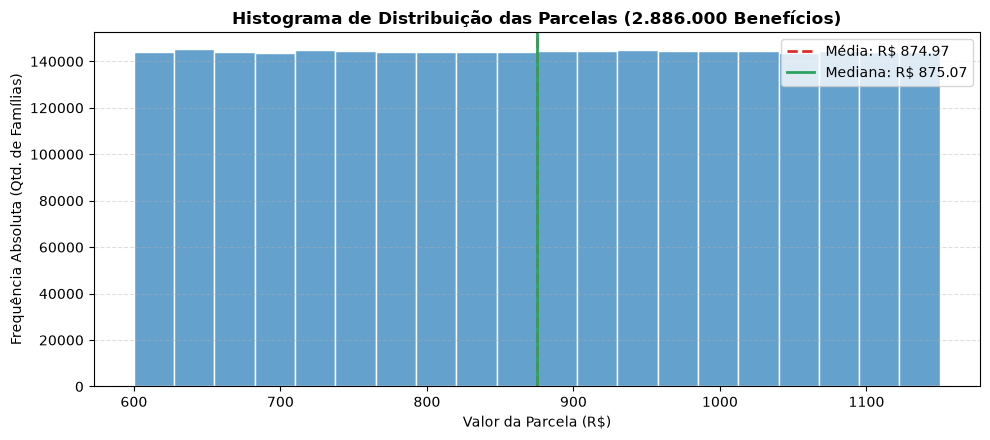

In [4]:
# Importa Matplotlib e Seaborn para gerar o histograma
import matplotlib.pyplot as plt
import seaborn as sns

# Lê APENAS a coluna VALOR_PARCELA do arquivo Parquet usando modo Lazy (Projection Pushdown)
serie_valores = (
    pl.scan_parquet(arquivo_pq)
    .select('VALOR_PARCELA')                                 # Traz apenas 1 coluna de 8 do disco!
    .collect()
    .to_series()                                             # Converte para Series do Polars
)

# Calcula Média e Mediana para marcar no gráfico
media_v = serie_valores.mean()
mediana_v = serie_valores.median()

# Configura o tamanho da figura
plt.figure(figsize=(10, 4.5))

# Plota o histograma dividindo os valores entre R$ 600 e R$ 1150 em 20 faixas (bins)
sns.histplot(serie_valores, bins=20, color='#3182bd', edgecolor='white')

# Adiciona linhas verticais indicando Média e Mediana
plt.axvline(media_v, color='#de2d26', linestyle='--', linewidth=2, label=f'Média: R$ {media_v:.2f}')
plt.axvline(mediana_v, color='#2ca25f', linestyle='-', linewidth=2, label=f'Mediana: R$ {mediana_v:.2f}')

# Adiciona título, rótulos dos eixos e legenda
plt.title('Histograma de Distribuição das Parcelas (2.886.000 Benefícios)', fontweight='bold')
plt.xlabel('Valor da Parcela (R$)')
plt.ylabel('Frequência Absoluta (Qtd. de Famílias)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

*Leitura Analítica (Exemplo 4 — Leitura do Histograma):*

O histograma apresenta um formato retangular equilibrado (**Distribuição Uniforme / Platicúrtica**), onde todas as 20 faixas de valores entre R$ 600 e R$ 1.150 têm aproximadamente a mesma altura (~144.300 famílias por faixa), fazendo com que a **Média (`R$ 875,00`)** e a **Mediana (`R$ 875,00`)** fiquem sobrepostas no centro exato do gráfico.

---
## Atividades Práticas (Do Básico ao Intermediário)

### ATIVIDADE 1 (Nível Básico) — Tabela de Frequência e Moda com `pl.Categorical`
Crie um `pl.DataFrame` representando 10 atendimentos de suporte da **Data Organized**:
```python
canais_atendimento = ['WhatsApp', 'Site', 'WhatsApp', 'Telefone', 'WhatsApp', 'App', 'Site', 'WhatsApp', 'App', 'Site']
```

**Faça:**
1. Crie um `pl.DataFrame` com a coluna `'Canal'` tipada diretamente como `dtype=pl.Categorical`.
2. Calcule a **Frequência Absoluta** (`pl.len()`) e a **Frequência Relativa (%)** de cada canal, ordenando do mais usado para o menos usado.
3. Identifique qual é o canal **Modal** (Moda).

In [ ]:
# Escreva aqui o código da Atividade 1 (Nível Básico):



### ATIVIDADE 2 (Nível Intermediário — Estudo de Valor Médio e Distribuição em Big Data),
A equipe gestora faz uma pergunta aberta ao analista de dados (simulando a rotina real de trabalho):
> *"Elabore um estudo sobre a base consolidada (`bolsa_familia_3meses.parquet`), no qual seja possível obter subsídios estatísticos necessários para apresentar um valor médio confiável dos repasses no estado do Rio de Janeiro (`RJ`) em Março (`202603`), acompanhado da frequência por município e do histograma da distribuição."*

**Faça:**
1. Usando `pl.scan_parquet('bolsa_familia_3meses.parquet')`, filtre `UF == 'RJ'` e `MES_COMPETENCIA == '202603'`, convertendo `NOME_MUNICIPIO` para `pl.Categorical`.
2. Calcule os subsídios estatísticos que provam se a média é confiável: **Média, Mediana, Distância Média-Mediana (%), Desvio Padrão (`ddof=0`), CV (%) e Assimetria (`.skew()`)**.
3. Gere a **Tabela de Frequência Absoluta e Relativa (%)** por `NOME_MUNICIPIO` nesse recorte.
4. Plote o **Histograma** de `VALOR_PARCELA` para o Rio de Janeiro em Março e escreva o seu veredito técnico: a média pode ser apresentada com segurança à diretoria?

In [ ]:
# Escreva aqui o código da Atividade 2 (Nível Intermediário):



*Leitura Analítica Final (Parecer Técnico para a Questão Aberta do PTD):*

**Sim, a média de `~R$ 875,00` pode ser apresentada com total segurança como indicador representativo!** Os subsídios estatísticos comprovam isso por três vias: (1) a **Distância Média-Mediana** é praticamente `0,0%` (bem abaixo do teto de `10%` do PTD), (2) a **Assimetria** é próxima de `0,00` (distribuição **Simétrica**) e (3) o **Histograma** confirma que não há distorção por valores extremos.